# Segmentación de clientes de tarjetas de crédito con Machine Learning
*Aprendizaje no supervisado (PCA + K-Means, contrastado con DBSCAN) para perfilar a los clientes y gestionar el riesgo de una cartera de tarjetas.*

---

## Resumen ejecutivo

En este notebook segmentamos a **8 950 titulares de tarjeta de crédito** a partir de **17 variables de comportamiento transaccional**: saldo, compras, anticipos de efectivo, pagos, límite de crédito, antigüedad y otras.

**Resultado principal.** Obtenemos **5 segmentos interpretables** con **K-Means sobre 6 componentes principales** (≈ 80.4 % de la varianza acumulada). Cada segmento se traduce en un perfil comercial con una acción concreta: desde los clientes de mayor gasto y frecuencia plena (≈ 22 % de la cartera) hasta un grupo que recurre a anticipos de efectivo con saldos altos y requiere seguimiento de riesgo (≈ 10 %). También probamos **DBSCAN** y lo descartamos, porque agrupa casi toda la cartera en un único macro-clúster y deja el resto como ruido.

| Hallazgo | Detalle |
| :--- | :--- |
| Calidad de datos | Sin duplicados. Nulos solo en `MINIMUM_PAYMENTS` (3.50 %) y `CREDIT_LIMIT` (1 registro) |
| Distribuciones | Fuerte asimetría y *outliers* en las variables monetarias, que atenuamos con `log1p` |
| Reducción de dimensionalidad | 6 componentes principales retienen ≈ 80.4 % de la varianza |
| Modelo final | K-Means con K = 5. Silueta ≈ 0.26: estructura moderada, propia de un comportamiento que varía de forma continua |
| Producto de negocio | Tabla de perfilado por mediana y plan de acción por segmento |

---

## Contexto y problema de negocio

Una entidad financiera quiere afinar sus campañas de marketing y mejorar la gestión del riesgo de su cartera de tarjetas. Hoy trata a todos los clientes por igual, de modo que las ofertas pierden efectividad y los comportamientos de riesgo se detectan tarde.

**Objetivo analítico:** aplicar **aprendizaje no supervisado** para descubrir patrones de uso que no se ven a simple vista y agrupar a los clientes en **segmentos homogéneos e interpretables** (*profiling*).

## Metodología y flujo de trabajo

Buscamos una segmentación estable, que no dependa de unos pocos valores extremos. El trabajo sigue estas fases:

1. **Carga e inspección de datos:** estructura, tipos, nulos y duplicados.
2. **Análisis exploratorio (EDA):** distribuciones, *outliers* y correlaciones.
3. **Preprocesamiento:**
   - Imputación de nulos con la **mediana**, que apenas se ve afectada por los *outliers*.
   - `np.log1p` sobre las variables monetarias para reducir su asimetría.
   - Escalado con `StandardScaler`.
4. **Reducción de dimensionalidad:** `PCA` con **6 componentes**, para resumir la información y eliminar redundancia (sección 4.4).
5. **Modelado y comparativa:** **K-Means** (K elegido con codo y silueta) frente a **DBSCAN** (ε elegido con el gráfico *k-distance*).
6. **Perfilado comercial:** volvemos a las variables originales y calculamos **medianas por clúster** para definir la estrategia de cada segmento.

## Estructura del notebook

| Sección | Contenido |
| :--- | :--- |
| 1 | Configuración del entorno y carga de datos |
| 2 | Inspección inicial y calidad de datos |
| 3 | Análisis exploratorio (EDA) |
| 4 | Preprocesamiento y reducción de dimensionalidad |
| 5 | Modelado I: K-Means |
| 6 | Modelado II: DBSCAN |
| 7 | Perfilado de segmentos y estrategia comercial |
| 8 | Conclusiones, limitaciones y próximos pasos |

## Descripción de las variables

El dataset (fichero `CC GENERAL.csv`) resume el uso que hacen de su tarjeta los titulares activos, según la documentación pública del conjunto de datos.

| Variable | Descripción |
| :--- | :--- |
| `CUST_ID` | Identificador único del titular. No se usa en el modelado. |
| `BALANCE` | Saldo medio pendiente que el cliente mantiene con el banco por el uso de la tarjeta. |
| `BALANCE_FREQUENCY` | Frecuencia con la que se actualiza el saldo de la cuenta (0 = casi nunca, 1 = con mucha frecuencia). |
| `PURCHASES` | Importe total acumulado de compras con la tarjeta en el periodo. |
| `ONEOFF_PURCHASES` | Importe total de compras pagadas en un único pago. |
| `INSTALLMENTS_PURCHASES` | Importe total de compras diferidas o financiadas a plazos. |
| `CASH_ADVANCE` | Importe total de efectivo retirado como anticipo con la tarjeta. |
| `PURCHASES_FREQUENCY` | Frecuencia de compra (de 0.0 a 1.0). |
| `ONEOFF_PURCHASES_FREQUENCY` | Frecuencia de compras de pago único. |
| `PURCHASES_INSTALLMENTS_FREQUENCY` | Frecuencia de compras a plazos. |
| `CASH_ADVANCE_FREQUENCY` | Frecuencia de retiradas de efectivo. |
| `CASH_ADVANCE_TRX` | Número total de retiradas de efectivo. |
| `PURCHASES_TRX` | Número total de operaciones de compra. |
| `CREDIT_LIMIT` | Límite máximo de crédito concedido al titular. |
| `PAYMENTS` | Importe total abonado por el cliente para saldar su deuda. |
| `MINIMUM_PAYMENTS` | Importe de los pagos mínimos requeridos o abonados. |
| `PRC_FULL_PAYMENT` | Proporción de periodos en los que el cliente pagó el 100 % del saldo pendiente. |
| `TENURE` | Antigüedad del cliente con la tarjeta, en meses (de 6 a 12). |

## Supuestos y alcance

- **No hay etiquetas (*ground truth*).** Valoramos la segmentación con métricas internas (inercia, silueta) y, sobre todo, con la interpretabilidad y la utilidad comercial de los perfiles.
- **Es una foto estática.** No hay dimensión temporal, así que los segmentos describen el comportamiento agregado del periodo, no su evolución.
- **Imputación por mediana.** Asumimos que los nulos (3.5 % en una sola variable) no sesgan de forma relevante la segmentación.
- **Perfiles por mediana.** Describen al cliente *típico* de cada segmento, no a los casos extremos.

---
# 1. Configuración del entorno y carga de datos

Importamos las librerías agrupadas por función. Con ellas cubrimos todo el flujo de trabajo: `pandas` y `numpy` para manipular datos, `matplotlib`, `seaborn` y `plotly` para visualizar (estático e interactivo) y `scikit-learn` para el modelado.

In [1]:
# Manipulación de datos.
import numpy as np
import pandas as pd

# Visualización: matplotlib y seaborn para el EDA (gráficos estáticos, fáciles de llevar a un informe);
# plotly para el 3D de los segmentos y el gráfico k-distance, donde interesa rotar y hacer zoom.
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Escalado: PCA, K-Means y DBSCAN trabajan con distancias y varianzas, así que sin escalar
# dominarían las variables de mayor magnitud.
from sklearn.preprocessing import StandardScaler

# Reducción de dimensionalidad: resume las variables y elimina redundancia entre ellas.
from sklearn.decomposition import PCA

# Modelado: K-Means (particional) y DBSCAN (basado en densidad) como enfoques complementarios.
from sklearn.cluster import DBSCAN, KMeans

# NearestNeighbors nos sirve para estimar el radio eps de DBSCAN (gráfico k-distance).
from sklearn.neighbors import NearestNeighbors

# Silueta: métrica interna de calidad del clustering (cohesión frente a separación) que no necesita etiquetas.
from sklearn.metrics import silhouette_score

In [2]:
# El CSV debe estar en el mismo directorio de trabajo que el notebook.
df = pd.read_csv("CC_GENERAL.csv")

---
# 2. Inspección inicial y calidad de datos

Antes de modelar revisamos tres cosas: la **estructura** de los datos (dimensiones y tipos), su **completitud** (nulos) y su **unicidad** (duplicados). Lo que encontremos aquí decide cómo limpiar. Y conviene hacerlo bien, porque en clustering no hay etiquetas que delaten un error de calidad: un problema en los datos acaba en los segmentos sin dar ningún aviso.

## 2.1 Dimensiones y tipos de datos

In [3]:
# Primer control: cuántos clientes (filas) y cuántas variables (columnas) tenemos.
print("Dimensiones del dataframe:", df.shape)

Dimensiones del dataframe: (8950, 18)


In [4]:
# Comprobamos que las variables numéricas se han leído como numéricas. Un tipo 'object' inesperado
# apuntaría a separadores decimales o símbolos mal codificados. Solo CUST_ID debe ser texto.
print("Tipos de datos en cada columna:")
print(df.dtypes)

Tipos de datos en cada columna:
CUST_ID                              object
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENTS                            float64
MINIMUM_PAYMENTS                    float64
PRC_FULL_PAYMENT                    float64
TENURE                                int64
dtype: object


In [5]:
# Vista previa del conjunto completo para familiarizarnos con escalas y formatos.
df

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


## 2.2 Valores nulos y duplicados

Cuantificamos los nulos en **valor absoluto y en porcentaje**, porque el porcentaje es lo que orienta la decisión: eliminar filas, imputar o descartar la variable. Aquí hay tan pocos que borrar filas supondría perder clientes válidos sin necesidad.

In [6]:
# Nulos por columna, en valor absoluto y como porcentaje del total de clientes.
null_values = df.isnull().sum()
null_values_percentage = (null_values / len(df)) * 100
print("Valores nulos por columna:")
print(null_values)
print("Porcentaje de valores nulos por columna:")
print(null_values_percentage)

# Porcentaje global de celdas vacías, para saber si el problema es generalizado o puntual.
# Aquí es puntual (0.19 %): solo MINIMUM_PAYMENTS (313 nulos, ~3.5 %) y CREDIT_LIMIT (1 nulo).
total_null_values = null_values.sum()
total_null_percentage = (total_null_values / (len(df) * len(df.columns))) * 100
print(f"Total de valores nulos en el dataset: {total_null_values}")
print(f"Porcentaje de valores nulos en el dataset: {total_null_percentage:.2f}%")

Valores nulos por columna:
CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64
Porcentaje de valores nulos por columna:
CUST_ID                             0.000000
BALANCE                             0.000000
BALANCE_FREQUENCY                   0.000000
PURCHASES                           0.000000
ONEOFF_PURCHASES   

In [7]:
# Una fila duplicada daría doble peso a un mismo cliente y desplazaría los centroides.
# Lo comprobamos sobre el dataframe completo, incluido CUST_ID, que debería ser único por cliente.
duplicate_rows = df.duplicated().sum()
print(f"Total de filas duplicadas en el dataset: {duplicate_rows}")

Total de filas duplicadas en el dataset: 0


## 2.3 Resumen estadístico

Transponemos `describe()` para leer una variable por fila. Hay que mirar dos cosas: la distancia entre la media y la mediana (percentil 50) y la que separa el percentil 75 del máximo. En `PURCHASES`, `CASH_ADVANCE` o `PAYMENTS`, la media queda claramente por encima de la mediana y el máximo es de otro orden de magnitud. Son señales de **asimetría positiva** y de ***outliers***, y anticipan que hará falta una transformación logarítmica.

In [8]:
# Con .T obtenemos una fila por variable, que con 17 columnas se lee mucho mejor.
summary_statistics = df.describe().T
print(summary_statistics)

                                   count         mean          std        min  \
BALANCE                           8950.0  1564.474828  2081.531879   0.000000   
BALANCE_FREQUENCY                 8950.0     0.877271     0.236904   0.000000   
PURCHASES                         8950.0  1003.204834  2136.634782   0.000000   
ONEOFF_PURCHASES                  8950.0   592.437371  1659.887917   0.000000   
INSTALLMENTS_PURCHASES            8950.0   411.067645   904.338115   0.000000   
CASH_ADVANCE                      8950.0   978.871112  2097.163877   0.000000   
PURCHASES_FREQUENCY               8950.0     0.490351     0.401371   0.000000   
ONEOFF_PURCHASES_FREQUENCY        8950.0     0.202458     0.298336   0.000000   
PURCHASES_INSTALLMENTS_FREQUENCY  8950.0     0.364437     0.397448   0.000000   
CASH_ADVANCE_FREQUENCY            8950.0     0.135144     0.200121   0.000000   
CASH_ADVANCE_TRX                  8950.0     3.248827     6.824647   0.000000   
PURCHASES_TRX               

## 2.4 Eliminación del identificador

`CUST_ID` es un código arbitrario, sin información de comportamiento. Si lo dejáramos, añadiría ruido al modelo y, si se codificara como número, hasta estructura inventada. Por eso lo quitamos antes del EDA y del modelado.

In [9]:
# Quitamos el identificador: no describe comportamiento y distorsionaría las distancias.
df = df.drop(columns=['CUST_ID'])
print(df.columns)  # Columnas que quedan tras eliminar CUST_ID.

Index(['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
       'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
       'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX',
       'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT',
       'TENURE'],
      dtype='object')


---
# 3. Análisis exploratorio de datos (EDA)

El EDA responde a tres preguntas que condicionan el preprocesamiento:

1. **¿Cómo se distribuyen las variables?** Su asimetría decide si hay que transformarlas.
2. **¿Hay valores atípicos?** Hay que decidir si se tratan o si basta con atenuarlos mediante una transformación.
3. **¿Hay redundancia entre variables?** La correlación justificará (o no) reducir la dimensionalidad con PCA.

## 3.1 Distribuciones univariantes

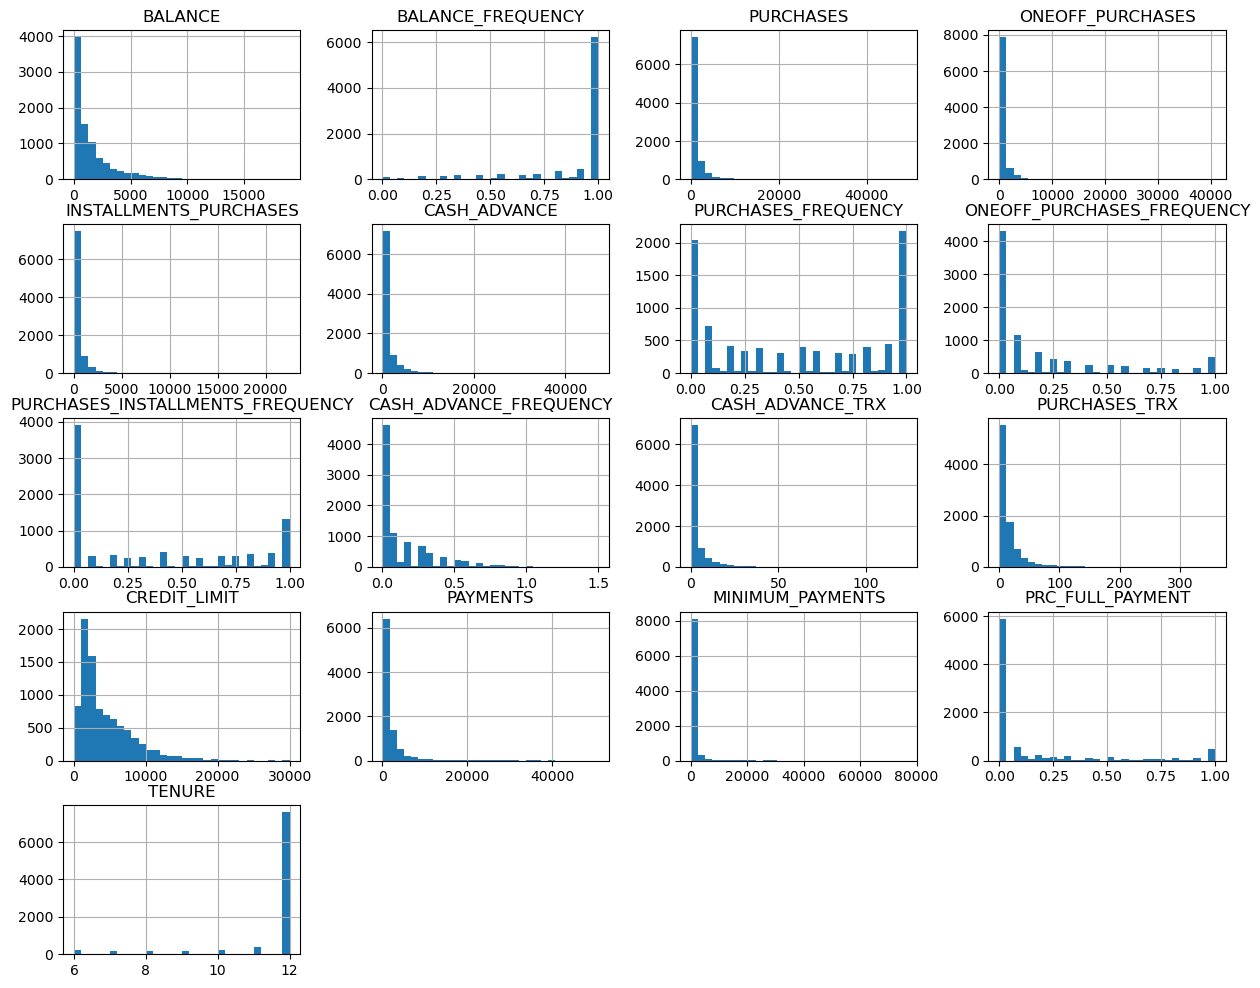

In [10]:
# Histogramas de todas las variables, para ver la forma de cada distribución.
# Con unas 9 000 observaciones, 30 intervalos dan buena resolución sin meter ruido.
df.hist(bins=30, figsize=(15, 12))
plt.show()

**Lectura.** Las variables monetarias (`BALANCE`, `PURCHASES`, `CASH_ADVANCE`, `PAYMENTS`…) y los contadores de transacciones tienen una **cola derecha muy larga** y se concentran cerca de cero. Las variables de frecuencia, acotadas entre 0 y 1, se acumulan en los extremos: hay clientes que nunca usan una funcionalidad y otros que la usan siempre. `BALANCE_FREQUENCY` se concentra en 1, y `TENURE` está dominada por el valor 12.

**Una anomalía menor.** `CASH_ADVANCE_FREQUENCY` llega a 1.5 (se aprecia en `describe()`), un valor imposible para una frecuencia, que debería moverse entre 0 y 1. Afecta a muy pocos registros y la tratamos en la sección 4.5, aunque conviene confirmarla con el equipo propietario del dato.

## 3.2 Detección de valores atípicos

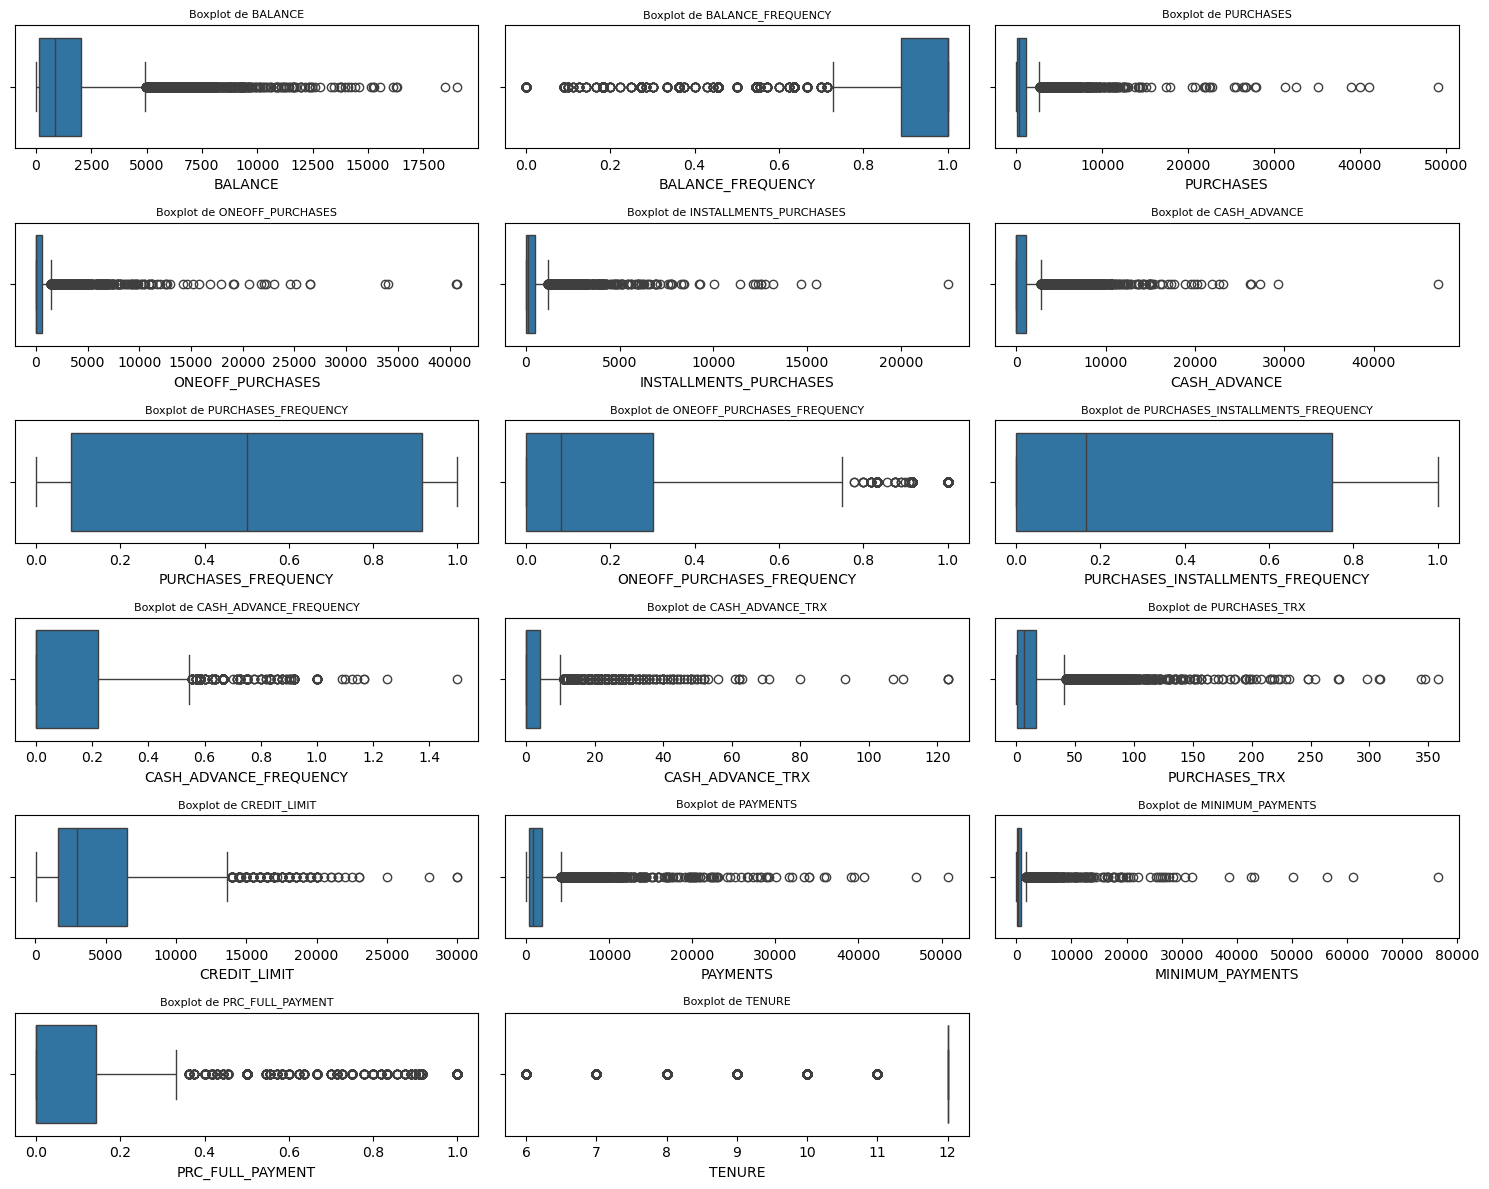

In [11]:
# Los diagramas de caja muestran los outliers de cada variable (puntos fuera de 1.5·IQR).
plt.figure(figsize=(15, 12))

for i, column in enumerate(df.columns):
    # Filtramos solo las columnas numéricas por prudencia, por si algún día se añaden categóricas.
    if df[column].dtype in ['int64', 'float64']:
        plt.subplot(6, 3, i + 1)  # Rejilla de 6x3 = 18 huecos para las 17 variables.
        sns.boxplot(x=df[column])
        plt.title(f'Boxplot de {column}', fontsize=8)

plt.tight_layout()  # Evita que títulos y ejes se solapen entre subgráficos.
plt.show()

**Lectura.** Los *outliers* son abundantes y no parecen errores de captura: corresponden a clientes con niveles de gasto o de deuda genuinamente altos. Eliminarlos nos dejaría sin los segmentos más interesantes para el negocio, como los grandes compradores o los usuarios intensivos de efectivo. Por eso, en lugar de borrarlos, **atenuamos su influencia con una transformación logarítmica**.

## 3.3 Correlaciones y redundancia entre variables

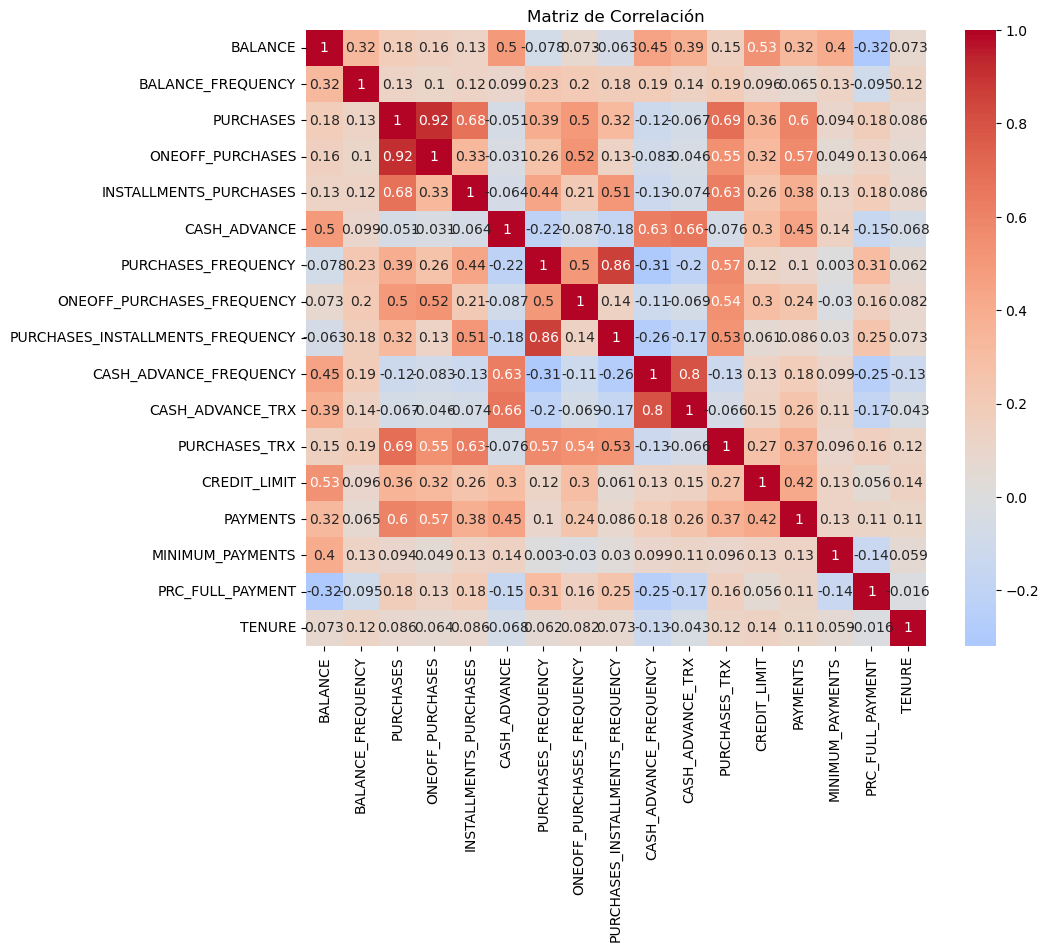

In [12]:
# Matriz de correlación de Pearson, que mide relaciones lineales entre pares de variables.
# Con center=0 en el mapa 'coolwarm', el color neutro corresponde a correlación nula.
correlation_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Matriz de Correlación')
plt.show()

In [13]:
# Para detectar redundancia importa la magnitud de la relación, no su signo: usamos el valor absoluto.
corr = df.corr().abs()
corr

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
BALANCE,1.000000,0.322412,0.181261,0.164350,0.126469,0.496692,0.077944,0.073166,0.063186,0.449218,0.385152,0.154338,0.531283,0.322802,0.398684,0.318959,0.072692
BALANCE_FREQUENCY,0.322412,1.000000,0.133674,0.104323,0.124292,0.099388,0.229715,0.202415,0.176079,0.191873,0.141555,0.189626,0.095843,0.065008,0.132569,0.095082,0.119776
PURCHASES,0.181261,0.133674,1.000000,0.916845,0.679896,0.051474,0.393017,0.498430,0.315567,0.120143,0.067175,0.689561,0.356963,0.603264,0.093860,0.180379,0.086288
ONEOFF_PURCHASES,0.164350,0.104323,0.916845,1.000000,0.330622,0.031326,0.264937,0.524891,0.127729,0.082628,0.046212,0.545523,0.319724,0.567292,0.048755,0.132763,0.064150
INSTALLMENTS_PURCHASES,0.126469,0.124292,0.679896,0.330622,1.000000,0.064244,0.442418,0.214042,0.511351,0.132318,0.073999,0.628108,0.256499,0.384084,0.132172,0.182569,0.086143
CASH_ADVANCE,0.496692,0.099388,0.051474,0.031326,0.064244,1.000000,0.215507,0.086754,0.177070,0.628522,0.656498,0.075850,0.303985,0.453238,0.140107,0.152935,0.068312
PURCHASES_FREQUENCY,0.077944,0.229715,0.393017,0.264937,0.442418,0.215507,1.000000,0.501343,0.862934,0.308478,0.203478,0.568430,0.119788,0.103464,0.003030,0.305802,0.061506
ONEOFF_PURCHASES_FREQUENCY,0.073166,0.202415,0.498430,0.524891,0.214042,0.086754,0.501343,1.000000,0.142329,0.111716,0.069088,0.544869,0.295038,0.243537,0.030327,0.157531,0.082466
PURCHASES_INSTALLMENTS_FREQUENCY,0.063186,0.176079,0.315567,0.127729,0.511351,0.177070,0.862934,0.142329,1.000000,0.262958,0.169207,0.529975,0.060755,0.085551,0.030073,0.250087,0.073275
CASH_ADVANCE_FREQUENCY,0.449218,0.191873,0.120143,0.082628,0.132318,0.628522,0.308478,0.111716,0.262958,1.000000,0.799561,0.131168,0.132616,0.183192,0.098838,0.249773,0.133372


In [14]:
# Seleccionamos las parejas distintas con correlación alta.
# Recorremos solo el triángulo superior (j > i) para no contar la diagonal (cada variable consigo
# misma, correlación 1) ni duplicar parejas simétricas, (A, B) y (B, A).
# Usamos 0.5 como umbral: es el criterio convencional de correlación moderada-alta.
threshold = 0.5
high_corr_pairs = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if corr.iloc[i, j] >= threshold:
            high_corr_pairs.append((corr.columns[i], corr.columns[j]))

print(f"Parejas con alta correlación: {len(high_corr_pairs)}")

Parejas con alta correlación: 18


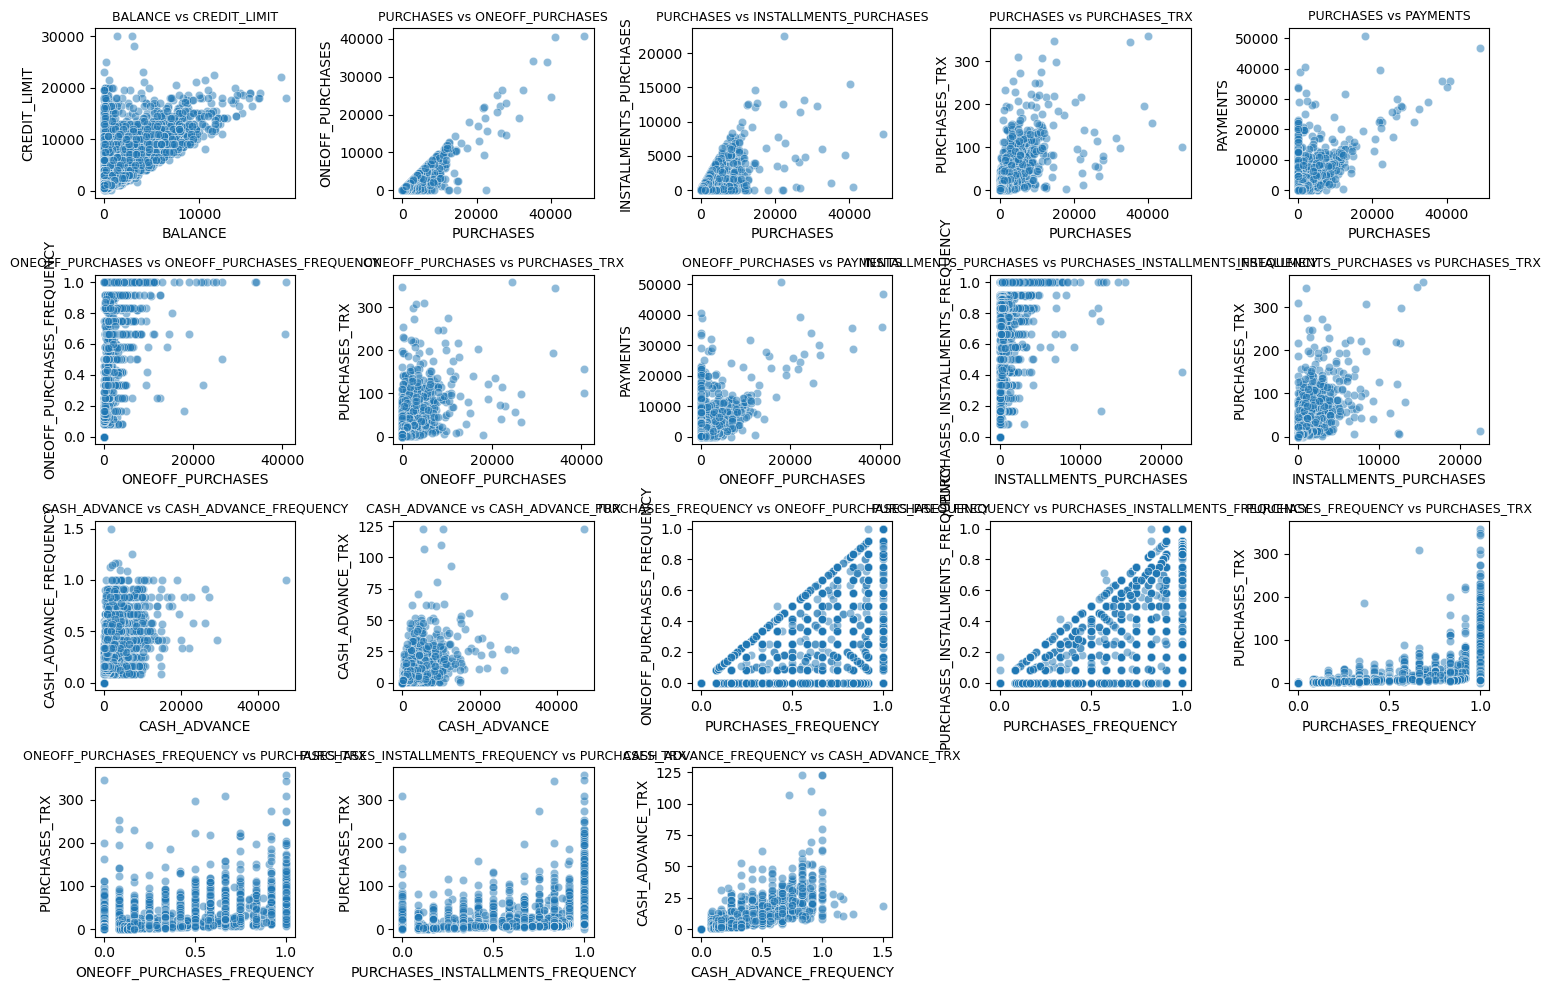

In [15]:
# Dispersión de cada pareja muy correlacionada, para confirmar a ojo que la relación es real
# (y no el efecto de unos pocos outliers) y ver qué forma tiene.
plt.figure(figsize=(15, 10))

for i, (var1, var2) in enumerate(high_corr_pairs):
    # Rejilla de 4x5 = 20 huecos, suficiente para las 18 parejas detectadas.
    plt.subplot(4, 5, i + 1)

    # alpha=0.5 deja ver la densidad donde se solapan los puntos (hay unos 9 000).
    sns.scatterplot(data=df, x=var1, y=var2, alpha=0.5)
    plt.title(f'{var1} vs {var2}', fontsize=9)

plt.tight_layout()
plt.show()

**Lectura.** Encontramos **18 parejas con correlación ≥ 0.5**, lo que confirma **multicolinealidad** entre grupos de variables:

- `PURCHASES` casi viene determinada por `ONEOFF_PURCHASES` (≈ 0.92) y, en menor medida, por `INSTALLMENTS_PURCHASES` (≈ 0.68), porque el total de compras es la suma de ambas.
- Las variables de importe, frecuencia y número de operaciones de un mismo concepto (`CASH_ADVANCE`, `CASH_ADVANCE_FREQUENCY` y `CASH_ADVANCE_TRX`, con correlaciones de ≈ 0.63 a 0.66) se mueven juntas.
- `PURCHASES_FREQUENCY` y `PURCHASES_INSTALLMENTS_FREQUENCY` son las más redundantes del conjunto (≈ 0.86).

Varias variables aportan, por tanto, casi la misma información, y sin tratamiento **pesarían de forma desproporcionada en las distancias** de K-Means. Es la justificación directa de aplicar **PCA**.

---
## Cierre del EDA y paso al preprocesamiento

Con esto damos por terminado el análisis exploratorio. En esta etapa hemos:

* revisado la estructura y la calidad de los datos originales;
* analizado las distribuciones, con una **asimetría (*skewness*)** y unos **valores atípicos** muy claros;
* evaluado las relaciones entre variables y confirmado la **multicolinealidad** entre las variables financieras y de comportamiento.

Con estos hallazgos construimos el *pipeline* de transformación que alimentará los modelos de *clustering*:

1. **Imputación de nulos:** mediana en `CREDIT_LIMIT` y `MINIMUM_PAYMENTS`, para que los *outliers* no sesguen el valor imputado.
2. **Transformación de distribuciones:** `np.log1p()` en las variables monetarias, para corregir la asimetría extrema y comprimir el efecto de los *outliers*.
3. **Escalado:** `StandardScaler()`, para dejar todas las variables con media 0 y varianza 1.
4. **Reducción de dimensionalidad:** **PCA**, para eliminar la redundancia antes de modelar con *K-Means* y *DBSCAN*.

---
# 4. Preprocesamiento y reducción de dimensionalidad

El orden del *pipeline* importa: **imputar → transformar (log) → escalar → PCA**. Imputamos primero porque ni `log1p`, ni `StandardScaler`, ni `PCA` admiten nulos. El logaritmo va antes del escalado porque estandarizar no corrige la asimetría. Y PCA va al final porque es sensible a la escala y necesita variables ya estandarizadas.

## 4.1 Imputación de valores nulos

Imputamos con la **mediana** y no con la media. En variables tan asimétricas, la media la arrastran los *outliers* y asignaría a los clientes sin dato un valor poco representativo. Como el problema afecta solo al 3.5 % de los registros (`MINIMUM_PAYMENTS`) y a un único registro (`CREDIT_LIMIT`), el impacto sobre los clústeres es mínimo.

In [16]:
# Imputamos con la mediana (poco sensible a outliers) las dos únicas columnas con nulos.
# Asignamos el resultado de fillna en lugar de usar inplace=True: ese patrón opera sobre una copia
# intermedia y dejará de funcionar en pandas 3.0.
df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].fillna(df['CREDIT_LIMIT'].median())
df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].median())

In [17]:
# Verificación tras la imputación: todas las columnas deben tener 0 nulos.
null_values = df.isnull().sum()
null_values_percentage = (null_values / len(df)) * 100
print("Valores nulos por columna:")
print(null_values)
print("Porcentaje de valores nulos por columna:")
print(null_values_percentage)

# El total global también debe ser 0 si la imputación ha sido completa.
total_null_values = null_values.sum()
total_null_percentage = (total_null_values / (len(df) * len(df.columns))) * 100
print(f"Total de valores nulos en el dataset: {total_null_values}")
print(f"Porcentaje de valores nulos en el dataset: {total_null_percentage:.2f}%")

Valores nulos por columna:
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64
Porcentaje de valores nulos por columna:
BALANCE                             0.0
BALANCE_FREQUENCY                   0.0
PURCHASES                           0.0
ONEOFF_PURCHASES                    0.0
INSTALLMENTS_PURCHASES              0.0
CASH_ADVANCE                        0.0
PURCHASES_FREQUENCY              

---
## 4.2 Transformación logarítmica de las variables monetarias

Aplicamos `log1p` a las variables de importe con asimetría marcada: saldo, compras (totales, en pago único y a plazos), anticipos de efectivo, límite de crédito, pagos y pagos mínimos. Usamos `log1p` y no `log` porque estas variables contienen ceros legítimos. El resto (frecuencias, contadores y antigüedad) se queda sin transformar.

Trabajamos sobre una copia, `df_log`, para que `df` conserve las unidades originales que necesitaremos en el perfilado final.

In [18]:
# Solo las columnas de importes con alta asimetría; el resto de variables no se transforma.
cols_to_log = [
    'BALANCE',
    'PURCHASES',
    'ONEOFF_PURCHASES',
    'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE',
    'CREDIT_LIMIT',
    'PAYMENTS',
    'MINIMUM_PAYMENTS'
]

# Copia para transformar: df conserva las unidades originales para el perfilado final.
df_log = df.copy()

# log1p en lugar de log, porque estas variables tienen ceros legítimos.
df_log[cols_to_log] = np.log1p(df_log[cols_to_log])

In [19]:
# Revisamos las estadísticas tras la transformación: los máximos deben haberse comprimido
# de forma drástica (BALANCE pasa de ~19 000 a ~9.9) y la media debe acercarse a la mediana.
df_log.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,6.161637,0.877271,4.899647,3.204274,3.352403,3.319086,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,8.094825,6.624540,5.916079,0.153715,11.517318
std,2.013303,0.236904,2.916872,3.246365,3.082973,3.566298,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,0.819629,1.591763,1.169929,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.931826,0.000000,0.018982,0.000000,6.000000
25%,4.861995,0.888889,3.704627,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,7.378384,5.951361,5.146667,0.000000,12.000000
50%,6.773521,1.000000,5.892417,3.663562,4.499810,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,8.006701,6.754489,5.747301,0.000000,12.000000
75%,7.628099,1.000000,7.013133,6.360274,6.151961,7.016449,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,8.779711,7.550732,6.671670,0.142857,12.000000
max,9.854515,1.000000,10.800403,10.615512,10.021315,10.760839,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,10.308986,10.834125,11.243832,1.000000,12.000000


## 4.3 Corrección de frecuencias fuera de rango

Una frecuencia es, por definición, una proporción entre 0 y 1. En el EDA vimos que `CASH_ADVANCE_FREQUENCY` llega a 1.5, un valor imposible que seguramente responde a un error de captura. Revisamos cuatro de las variables de frecuencia y truncamos (*clipping*) en 1.0 la que se pasa del límite, sin eliminar filas de la cartera.

Una precisión sobre el orden: este ajuste se aplica sobre `df` **después** de haber generado el espacio PCA. Por eso no cambia el entrenamiento de los modelos, aunque sí afecta a los centroides y a los perfiles que se calculan desde `df`. En una próxima iteración conviene moverlo antes de la transformación y el escalado (ver sección 8.2).

In [20]:
# Revisamos cuántos registros superan el máximo teórico de 1 en las variables de frecuencia.
frequency_cols = [
    'CASH_ADVANCE_FREQUENCY',
    'BALANCE_FREQUENCY',
    'ONEOFF_PURCHASES_FREQUENCY',
    'PURCHASES_INSTALLMENTS_FREQUENCY'
]

for col in frequency_cols:
    print(f"Registros donde {col} es mayor que 1: {(df[col] > 1).sum()}")

Registros donde CASH_ADVANCE_FREQUENCY es mayor que 1: 8
Registros donde BALANCE_FREQUENCY es mayor que 1: 0
Registros donde ONEOFF_PURCHASES_FREQUENCY es mayor que 1: 0
Registros donde PURCHASES_INSTALLMENTS_FREQUENCY es mayor que 1: 0


In [21]:
# Truncamos en 1.0 la única variable que se pasa del límite.
df['CASH_ADVANCE_FREQUENCY'] = df['CASH_ADVANCE_FREQUENCY'].clip(upper=1.0)
print("Máximo valor actual:", df['CASH_ADVANCE_FREQUENCY'].max())

Máximo valor actual: 1.0


## 4.4 Escalado de variables

`StandardScaler` centra cada variable en media 0 y varianza 1. Hace falta porque, incluso tras el logaritmo, los rangos siguen siendo muy distintos: frecuencias entre 0 y 1, importes en escala logarítmica de hasta ~10, o `PURCHASES_TRX`, que llega a 358. Sin escalar, PCA, K-Means y DBSCAN **darían más peso a las variables con mayor varianza**. Con el escalado, todas parten en igualdad de condiciones.

In [22]:
# fit_transform aprende la media y la desviación de cada columna y las aplica en un solo paso.
# Devuelve un array de numpy, así que lo convertimos de nuevo en DataFrame para conservar los
# nombres de columna y leer con facilidad los resultados posteriores.
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_log)
df_scaled = pd.DataFrame(df_scaled, columns=df_log.columns)
df_scaled

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-1.205218,-0.249434,-0.113532,-0.987090,0.394480,-0.930733,-0.806490,-0.678661,-0.707313,-0.675349,-0.476070,-0.511333,-1.447163,-0.824484,-0.829841,-0.525551,0.360680
1,0.948918,0.134325,-1.679855,-0.987090,-1.087454,1.528788,-1.221758,-0.678661,-0.916995,0.573963,0.110074,-0.591796,0.926060,1.065033,0.908184,0.234227,0.360680
2,0.824993,0.518084,0.600727,1.062022,-1.087454,-0.930733,1.269843,2.673451,-0.916995,-0.675349,-0.476070,-0.109020,1.010229,-0.119300,0.450407,-0.525551,0.360680
3,0.624653,-1.016953,0.827499,1.265778,-1.087454,0.564372,-1.014125,-0.399319,-0.916995,-0.258913,-0.329534,-0.551565,1.010229,-4.161996,-0.144271,-0.525551,0.360680
4,0.271260,0.518084,-0.708481,-0.114307,-1.087454,-0.930733,-1.014125,-0.399319,-0.916995,-0.675349,-0.476070,-0.551565,-1.224909,-0.064979,-0.351833,-0.525551,0.360680
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,-1.379634,0.518084,0.266574,-0.987090,0.754107,-0.930733,1.269843,-0.678661,1.179833,-0.675349,-0.476070,-0.350408,-1.447163,-0.525121,-1.715012,1.183951,-4.122768
8946,-1.568051,0.518084,0.276841,-0.987090,0.763821,-0.930733,1.269843,-0.678661,1.179833,-0.675349,-0.476070,-0.350408,-1.447163,-0.628912,-0.144271,-0.525551,-4.122768
8947,-1.473834,-0.185477,0.027374,-0.987090,0.527794,-0.930733,0.854576,-0.678661,0.760469,-0.675349,-0.476070,-0.390639,-1.447163,-1.391318,-1.275542,0.329200,-4.122768
8948,-1.733775,-0.185477,-1.679855,-0.987090,-1.087454,0.086038,-1.221758,-0.678661,-0.916995,0.157527,-0.182998,-0.591796,-2.291676,-1.661097,-1.604737,0.329200,-4.122768


## 4.5 Reducción de dimensionalidad con PCA

**Para qué.** PCA proyecta las 17 variables, correlacionadas entre sí, sobre componentes **ortogonales** (no correlacionados) y ordenados por la varianza que explican. Con ello:
- Se **elimina la redundancia** detectada en el EDA, de modo que grupos de variables casi idénticas no dominen las distancias.
- Se **reduce el ruido y la dimensión**, lo que ayuda a los algoritmos basados en distancia frente a la maldición de la dimensionalidad.

**Cómo.** Primero ajustamos un PCA con **todos** los componentes para ver cuánta varianza acumulan y, con esa información, decidimos cuántos conservar.

In [23]:
# PCA sin límite de componentes, solo para inspeccionar cuánta varianza aporta cada uno.
# (df_pca se vuelve a calcular más abajo con la versión final de 6 componentes.)
pca = PCA()
df_pca = pca.fit_transform(df_scaled)
df_pca = pd.DataFrame(df_pca, columns=[f'PC{i+1}' for i in range(df_pca.shape[1])])

In [24]:
# Varianza explicada acumulada (%) por componente. Nos ayuda a decidir cuántos conservar,
# equilibrando información retenida y reducción de dimensión.
pd.Series(np.cumsum(pca.explained_variance_ratio_ * 100), index=df_pca.columns)

PC1      29.861658
PC2      51.772257
PC3      61.111768
PC4      68.796436
PC5      75.311724
PC6      80.359704
PC7      84.607340
PC8      87.841106
PC9      90.946076
PC10     93.511488
PC11     95.434557
PC12     96.988720
PC13     97.839704
PC14     98.669260
PC15     99.297929
PC16     99.842045
PC17    100.000000
dtype: float64

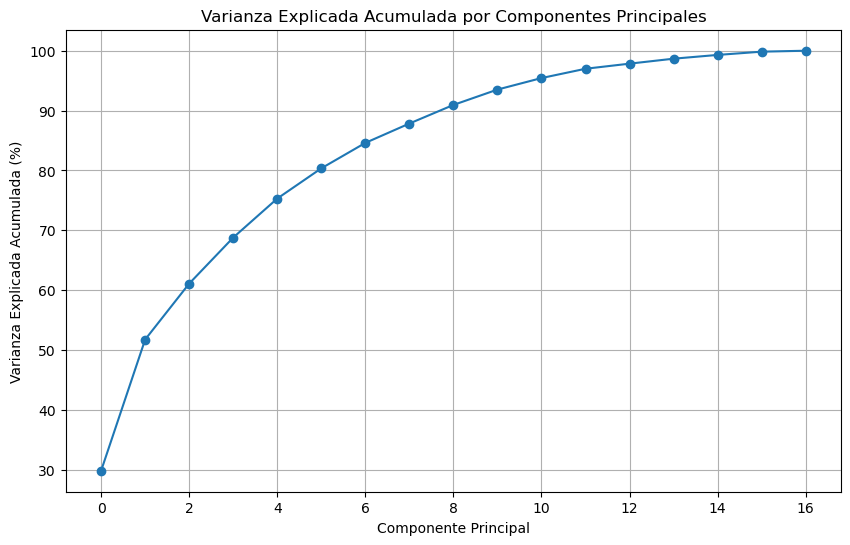

In [25]:
# Mismo dato en gráfico: buscamos el punto donde la curva se aplana (rendimientos decrecientes).
plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_ * 100), marker='o')
plt.title('Varianza Explicada Acumulada por Componentes Principales')
plt.xlabel('Componente Principal')
plt.ylabel('Varianza Explicada Acumulada (%)')
plt.grid(True)
plt.show()

**Decisión: 6 componentes principales (≈ 80.4 % de la varianza).** La curva no tiene un codo claro, así que aplicamos el criterio práctico de conservar en torno al **80 % de la varianza**. Con 6 componentes llegamos al 80.36 %, y cada componente adicional aporta menos de 5 puntos porcentuales. Es un compromiso razonable entre la fidelidad de la información y la sencillez del espacio sobre el que haremos el clustering.

In [26]:
# Modelo PCA final con 6 componentes. Fijamos random_state=42 por reproducibilidad: con tan pocas
# variables la descomposición es determinista, pero así evitamos diferencias si cambia el solver.
# A partir de aquí df_pca contiene el espacio reducido (n x 6).
pca_final = PCA(n_components=6, random_state=42)
df_pca = pca_final.fit_transform(df_scaled)
df_pca = pd.DataFrame(df_pca, columns=[f'PC{i+1}' for i in range(df_pca.shape[1])])

---
# 5. Modelado I: K-Means

**Por qué K-Means.** Es el método de referencia para segmentar clientes: escala bien, asigna cada cliente a un segmento y sus centroides se interpretan con facilidad en términos de negocio.

**Qué hay que tener en cuenta.** K-Means asume clústeres más o menos esféricos y de tamaño parecido, y exige fijar **K de antemano**. Por eso evaluamos varios valores de K con dos criterios que se complementan:

- **Método del codo (inercia).** Mide la compacidad interna, es decir, la suma de distancias cuadráticas a los centroides. Siempre baja al aumentar K, así que buscamos el punto donde las mejoras empiezan a ser marginales.
- **Coeficiente de silueta.** Mide a la vez la cohesión y la separación entre clústeres (va de -1 a 1). A diferencia de la inercia, no mejora automáticamente al subir K.

Entrenamos sobre el espacio PCA (6 componentes), no sobre las variables originales.

## 5.1 Selección del número de clústeres: método del codo

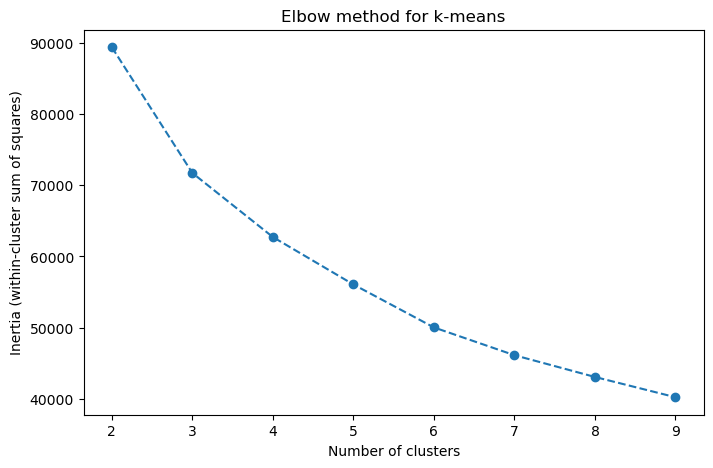

In [27]:
# Inercia (WCSS) de K-Means para distintos valores de K.
inertia = []

# Rango evaluado: K=1 no tiene sentido (no hay partición) y con K>9 los segmentos serían
# demasiado pequeños para ser accionables comercialmente.
range_n_clusters = range(2, 10)

for k in range_n_clusters:

    # n_init=10: lanzamos 10 inicializaciones aleatorias y nos quedamos con la mejor, para reducir
    # la sensibilidad de K-Means a la semilla. random_state=42 garantiza la reproducibilidad.
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_pca)

    # Inercia: suma de distancias cuadráticas de cada punto a su centroide.
    inertia.append(kmeans.inertia_)

# Gráfico del método del codo.
plt.figure(figsize=(8, 5))
plt.plot(range_n_clusters, inertia, marker='o', linestyle='--')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.title('Elbow method for k-means')
plt.show()

## 5.2 Selección del número de clústeres: coeficiente de silueta

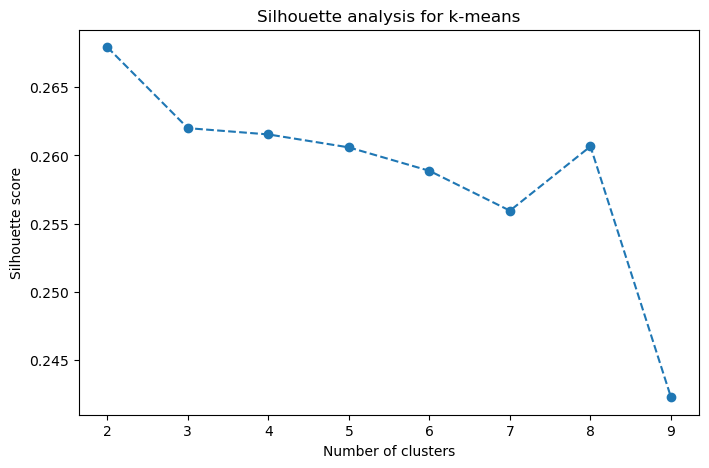

In [28]:
# Silueta media para cada K. A diferencia de la inercia, penaliza los clústeres solapados, así que
# nos dice cuándo añadir clústeres deja de aportar separación real.
silhouette_scores = []

for k in range_n_clusters:

    # Misma configuración que en el método del codo, para que ambos criterios sean comparables.
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_pca)

    # silhouette_score calcula distancias por pares (O(n²)); con ~9 000 filas es asumible.
    # En carteras mucho mayores convendría usar el parámetro sample_size.
    silhouette_scores.append(silhouette_score(df_pca, kmeans.labels_))

# Gráfico de la silueta por K.
plt.figure(figsize=(8, 5))
plt.plot(range_n_clusters, silhouette_scores, marker='o', linestyle='--')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.title('Silhouette analysis for k-means')
plt.show()

## 5.3 Elección definitiva del número de clústeres ($K=5$)

Tras cruzar el método del codo y la silueta, nos quedamos con **$K = 5$** por tres razones:

1. **La silueta apenas distingue entre opciones.** Hay un pequeño repunte en $K=8$ ($S \approx 0.2608$), pero la diferencia con $K=5$ ($S \approx 0.2606$) es inferior a $0.001$. Como la silueta se mantiene prácticamente plana entre $K=3$ y $K=8$, guiarnos por ese pico supondría sobre-segmentar sin una ganancia estadística real. El máximo absoluto está en $K=2$, pero dos grupos son demasiado pocos para un uso comercial.
2. **La inercia no muestra un codo nítido.** Desciende de forma gradual y los rendimientos decrecientes se notan a partir de $K \in [4, 5]$, sin un quiebre claro. Usamos el codo como criterio de apoyo, no como decisivo.
3. **Equilibrio entre rigor técnico y negocio.** Cinco segmentos dan suficiente granularidad para diseñar estrategias diferenciadas sin fragmentar la base de clientes más de lo necesario.

> **Cómo leer la silueta (≈ 0.26).** Un valor en este entorno indica una estructura de clústeres entre moderada y débil: los segmentos tienen identidad propia, pero se solapan en sus fronteras. Tiene sentido, porque el comportamiento financiero varía de forma continua y no en grupos claramente separados (lo retomamos con DBSCAN en la sección 6).

## 5.4 Entrenamiento del modelo final y centroides

In [29]:
# Número de clústeres elegido en la sección 5.3.
k_optimal = 5

# Misma configuración que en la búsqueda de K (n_init=10, random_state=42), para que el modelo
# final sea reproducible y coherente con lo que evaluamos antes.
kmeans = KMeans(n_clusters=k_optimal, n_init=10, random_state=42)

# Guardamos la etiqueta en df (variables originales, interpretables) y en df_pca (el espacio donde
# entrenamos, útil para graficar). Se alinean por índice porque no hemos filtrado ni reordenado
# filas desde la carga: la fila i de df_pca corresponde a la fila i de df.
df['Cluster_k-means'] = kmeans.fit_predict(df_pca)
df_pca['Cluster_k-means'] = df['Cluster_k-means']

# "Centroides" en unidades originales: media de cada variable por clúster. Los calculamos sobre df
# (sin transformar) para poder leerlos en términos de negocio (importes, frecuencias...).
# Ojo: la media es sensible a los outliers, por eso el perfilado final (sección 7) usa la mediana.
centroids_not_scaled = df.groupby('Cluster_k-means').mean()
centroids_not_scaled

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster_k-means,,,,,,,,,,,,,,,,,
0,2036.832288,0.941074,102.680683,94.630219,8.117581,1541.258026,0.059920,0.047157,0.012235,0.226862,4.627829,1.029685,3803.273177,1424.045128,994.823020,0.027279,11.426716
1,1695.001721,0.976353,2923.807542,1999.143659,924.688310,204.261362,0.850612,0.620182,0.547360,0.035159,0.621635,38.763210,6347.472129,2822.117820,844.710742,0.228949,11.863410
2,4315.299057,0.977214,1155.255045,670.734036,484.559933,4226.950052,0.579444,0.253951,0.416625,0.497118,15.540359,18.141256,7148.262332,3742.115769,1787.730695,0.036423,11.465247
3,74.380155,0.430859,336.945202,237.879565,99.510061,139.479060,0.275173,0.099505,0.167167,0.023501,0.437739,4.201681,3758.698752,728.548622,147.588217,0.193298,11.282659
4,569.337332,0.938059,666.627012,62.170283,605.355303,119.355590,0.802616,0.041038,0.752093,0.025335,0.450684,14.373535,2902.632403,840.346728,682.875498,0.272187,11.470215


## 5.5 Visualización de los segmentos en el espacio de componentes principales

Proyectamos a los clientes sobre los **tres primeros componentes** (≈ 61 % de la varianza total) en un gráfico 3D interactivo. Es una vista parcial del espacio de 6 dimensiones en el que entrenamos el modelo, así que es normal ver cierto solapamiento entre clústeres que sí se separan en las dimensiones restantes.

In [30]:
# Trabajamos sobre una copia para no alterar df_pca. Convertimos el clúster a texto para que plotly
# lo trate como categoría (leyenda con 5 colores) y no como una escala continua.
df_grafica = df_pca.copy()
df_grafica["Cluster"] = df_grafica["Cluster_k-means"].astype(str)

# Gráfico 3D interactivo: se puede rotar y hacer zoom para explorar las fronteras entre segmentos.
fig = px.scatter_3d(
    df_grafica,
    x="PC1",
    y="PC2",
    z="PC3",
    color="Cluster",
    color_discrete_sequence=px.colors.qualitative.Set1,
    title="Segmentación K-Means en Espacio 3D (PC1, PC2, PC3)",
    opacity=0.7
)

# Puntos pequeños y semitransparentes para no saturar la vista con ~9 000 observaciones.
fig.update_traces(marker=dict(size=4))

fig.show()

## 5.6 Tamaño de los segmentos

Comprobamos que ningún clúster sea residual ni excesivamente dominante: un segmento diminuto sería poco accionable, y uno gigante indicaría una partición poco informativa.

In [31]:
# Número de clientes por clúster (K-Means, K=5). La suma debe coincidir con el total de la cartera.
for i in range(0, 5):
    cluster_data = df[df['Cluster_k-means'] == i]
    print(f"Observaciones en el Cluster {i}:")
    print(len(cluster_data))

# Control de coherencia: 893 + 2695 + 1309 + 2048 + 2005 = 8 950.
print(f"Observaciones totales en el dataset: {len(df)}")

Observaciones en el Cluster 0:
2695
Observaciones en el Cluster 1:
2006
Observaciones en el Cluster 2:
892
Observaciones en el Cluster 3:
1309
Observaciones en el Cluster 4:
2048
Observaciones totales en el dataset: 8950


**Lectura.** Los tamaños van del ≈ 10 % (clúster 0) al ≈ 30 % (clúster 1) de la cartera y suman exactamente las 8 950 observaciones. La partición está razonablemente equilibrada y todos los segmentos tienen volumen suficiente para justificar una estrategia propia.

---
# 6. Modelado II: DBSCAN (alternativa basada en densidad)

**Motivación.** DBSCAN no necesita que fijemos el número de clústeres, detecta **formas arbitrarias** y marca explícitamente el **ruido** (*outliers*, etiqueta `-1`). Lo usamos como contraste para ver si los datos tienen grupos naturales separados por zonas de baja densidad.

**Hiperparámetros.**
- `min_samples` (*minPts*): aplicamos la regla heurística **2 × dimensión**, habitual cuando no se dispone de conocimiento previo del dominio.
- `eps` (ε, radio de vecindad): lo estimamos con el gráfico *k-distance*, buscando el "codo" donde las distancias al k-ésimo vecino se disparan, que marca la frontera entre puntos densos y ruido.

## 6.1 Parámetro `min_samples`

In [32]:
# Número mínimo de puntos para formar un clúster (heurística minPts = 2 × dimensiones).
# Excluimos la última columna de df_pca, que es la etiqueta de K-Means y no una dimensión.
minPts = 2 * (df_pca.iloc[:, :-1]).shape[1]
print(f'Minimum number of points to form a cluster: {minPts}')

Minimum number of points to form a cluster: 12


In [33]:
# NearestNeighbors y DBSCAN fallan si hay NaN, así que verificamos que no haya ninguno.
df_pca.isna().sum()

PC1                0
PC2                0
PC3                0
PC4                0
PC5                0
PC6                0
Cluster_k-means    0
dtype: int64

## 6.2 Estimación de ε con el gráfico *k-distance*

Para cada punto calculamos la distancia a su k-ésimo vecino más cercano (con k = `minPts`) y las ordenamos de menor a mayor. El punto de inflexión de la curva sugiere un ε razonable: por debajo, los puntos están en zonas densas; por encima, en zonas dispersas o de ruido.

In [34]:
# Distancia de cada punto a su k-ésimo vecino más cercano, con k = minPts.
k = minPts
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(df_pca)
distances, indices = neighbors_fit.kneighbors(df_pca)

# Ordenamos la distancia al k-ésimo vecino (última columna). Su gráfico es la curva k-distance,
# cuyo "codo" orienta la elección de eps.
k_distances = np.sort(distances[:, -1])

# Gráfico interactivo: plotly permite hacer zoom sobre la zona del codo.
fig = go.Figure()

fig.add_trace(go.Scatter(
    y=k_distances,
    mode='lines+markers',
    line=dict(color='royalblue'),
    marker=dict(size=5),
    name=f'{k}-th Nearest Neighbor Distance'
))

fig.update_layout(
    title=f'{k}-Distance plot (for ε selection)',
    xaxis_title=f'Points sorted by distance to {k}th nearest neighbor',
    yaxis_title='Distance',
    template='plotly_white',
    hovermode='x unified',
    height=400,
    width=800
)

fig.show()

> **Nota técnica.** El gráfico se calcula sobre `df_pca` completo, que en este punto incluye la columna `Cluster_k-means` además de los 6 componentes. El ajuste de DBSCAN (siguiente celda), en cambio, **excluye** esa columna (`iloc[:, :-1]`). Es una pequeña incoherencia entre la estimación de ε y el modelo ajustado. No la corregimos aquí para no alterar los resultados y queda anotada como mejora en la sección 8.2.

**Lectura.** Con ε = 2, aproximadamente el **97.0 % de los puntos** tiene una k-distance (k = 12) menor o igual a 2, según los datos del gráfico. A partir de ahí la curva se dispara hacia valores extremos (el máximo ronda 7.3). Adoptamos `eps = 2` como punto de corte entre la masa densa y la cola dispersa.

## 6.3 Ajuste de DBSCAN y comparación con K-Means

In [35]:
# eps elegido a partir del gráfico k-distance (sección 6.2).
eps_opt = 2
dbscan_final = DBSCAN(eps=eps_opt, min_samples=minPts)

# Entrenamos solo con los componentes principales (iloc[:, :-1] deja fuera la columna de etiquetas
# 'Cluster_k-means'), para no usar el resultado de K-Means como variable de entrada.
df['Cluster_DBSCAN'] = dbscan_final.fit_predict(df_pca.iloc[:, :-1])

In [36]:
# Contamos las filas en las que las dos etiquetas difieren. Ojo: comparar así los identificadores
# de clúster dice poco, porque los números son arbitrarios y no equivalen entre algoritmos (DBSCAN
# usa -1 para el ruido). Una comparación rigurosa usaría una métrica invariante a permutaciones,
# como el ARI.
print("Cantidad de datos donde 'Cluster_DBSCAN' no es igual a 'Cluster_k-means':", df[df['Cluster_DBSCAN'] != df['Cluster_k-means']].shape[0])

Cantidad de datos donde 'Cluster_DBSCAN' no es igual a 'Cluster_k-means': 6256


In [37]:
# Etiquetas distintas que produce cada algoritmo. DBSCAN: {-1 (ruido), 0}; K-Means: {0..4}.
# Que DBSCAN devuelva un único clúster real (0) más ruido es el hallazgo clave de esta sección.
print("Valores distintos para 'Cluster_DBSCAN':", np.sort(df['Cluster_DBSCAN'].unique()))
print("Valores distintos para 'Cluster_k-means':", np.sort(df['Cluster_k-means'].unique()))

Valores distintos para 'Cluster_DBSCAN': [-1  0]
Valores distintos para 'Cluster_k-means': [0 1 2 3 4]


## 6.4 Discusión: por qué DBSCAN no encaja y K-Means sí

Aplicado sobre el espacio de componentes principales, DBSCAN generó solo dos grupos: el clúster `0`, que reúne a casi toda la cartera, y el `-1`, reservado para observaciones atípicas o ruido. Es un resultado habitual con datos transaccionales y financieros, y tiene tres explicaciones:

1. **La densidad es continua.** A diferencia de otros dominios, donde hay clases aisladas por vacíos de información, los hábitos de consumo y los saldos de las tarjetas forman un degradado. Los perfiles de usuario cambian de forma progresiva y se conectan unos con otros, sin fronteras de densidad evidentes.
2. **Hiperconectividad.** Sin zonas de baja densidad que delimiten grupos naturales, el criterio de vecindad de DBSCAN ($\epsilon$ y `min_samples`) enlaza transitivamente toda la masa principal de datos en un único macro-clúster.
3. **Utilidad comercial de K-Means.** Como DBSCAN no logra particiones útiles, elegimos **K-Means ($K=5$)** como modelo definitivo. K-Means no depende de valles de densidad: reparte el espacio con fronteras de Voronoi y permite dividir la cartera en segmentos finitos, homogéneos y comparables entre sí. Es lo que necesitamos para caracterizar perfiles, ponerles nombre y diseñar estrategias de marketing personalizadas.

> **Alcance de la conclusión.** No exploramos la sensibilidad a `eps` y `min_samples` (un ε menor, por ejemplo, podría fragmentar la masa densa). Aun así, el resultado es coherente con la silueta moderada de K-Means: los datos no presentan fronteras de densidad nítidas.

---
# 7. Perfilado de segmentos y estrategia comercial

Un clúster solo aporta valor al negocio si se puede **describir y nombrar**. Para ello volvemos a las **variables originales**, sin logaritmo ni escalado, que sí tienen significado económico directo.

**Por qué la mediana y no la media.** Las variables monetarias están muy sesgadas y unos pocos clientes extremos desplazan la media del grupo. La **mediana** describe al cliente *típico* de cada segmento y es coherente con la decisión que tomamos en el preprocesamiento de preferir estadísticos poco sensibles a los *outliers*.

In [38]:
# Quitamos la etiqueta de DBSCAN: el modelo final es K-Means, y mantener una segunda etiqueta
# contaminaría el groupby y las tablas de perfilado.
df = df.drop(columns=['Cluster_DBSCAN'])

In [39]:
# Revisión del dataframe final: variables originales (con los nulos ya imputados) más la etiqueta de clúster.
df

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Cluster_k-means
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,3
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,0
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,1
3,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,312.343947,0.000000,12,3
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6,4
8946,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,312.343947,0.000000,6,4
8947,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6,4
8948,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6,3


In [40]:
# ---------------------------------------------------------------------------
# Tabla de perfilado ejecutivo por clúster
# ---------------------------------------------------------------------------

# 1. Variables clave de negocio: las que mejor distinguen el comportamiento de gasto, el uso de
# efectivo, la solvencia y la capacidad. Dejamos fuera el resto para que la tabla sea legible.
vars_clave = [
    'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES',
    'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
    'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY',
    'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS'
]

# 2. Mediana por clúster: perfil representativo y poco sensible a outliers.
profiling_medianas = df.groupby('Cluster_k-means')[vars_clave].median().round(2)

# 3. Volumen y peso relativo (% de la cartera) de cada segmento, para priorizar acciones por
# impacto potencial. sort_index() alinea el orden con el de las medianas.
conteo = df['Cluster_k-means'].value_counts().sort_index()
porcentaje = (df['Cluster_k-means'].value_counts(normalize=True).sort_index() * 100).round(2)

# 4. Consolidación: insertamos tamaño y peso al principio, para que sea lo primero que se lea.
profiling_tabla = profiling_medianas.copy()
profiling_tabla.insert(0, 'Num_Clientes', conteo)
profiling_tabla.insert(1, '%_Cartera', porcentaje)

# Exportamos la tabla para el informe o el repositorio (se guarda en el directorio de trabajo).
profiling_tabla.to_csv('resumen_profiling_clusters.csv')
print("--- Tabla de Perfilado Ejecutivo (Medianas) ---")

# Con .T los clústeres quedan en columnas, lo que facilita comparar variables.
profiling_tabla.T

--- Tabla de Perfilado Ejecutivo (Medianas) ---


Cluster_k-means,0,1,2,3,4
Num_Clientes,2695.00,2006.00,892.00,1309.00,2048.00
%_Cartera,30.11,22.41,9.97,14.63,22.88
BALANCE,1439.34,973.58,3814.74,21.99,176.78
PURCHASES,0.00,1962.52,670.90,177.00,472.72
ONEOFF_PURCHASES,0.00,1219.84,279.15,20.09,0.00
INSTALLMENTS_PURCHASES,0.00,462.06,210.48,0.00,418.78
CASH_ADVANCE,938.57,0.00,3214.97,0.00,0.00
PURCHASES_FREQUENCY,0.00,1.00,0.58,0.20,0.92
CASH_ADVANCE_FREQUENCY,0.17,0.00,0.50,0.00,0.00
CREDIT_LIMIT,3000.00,6000.00,7000.00,3000.00,2000.00


## 7.1 Interpretación y plan de acción por segmento

La tabla traduce las medianas de cada clúster en un **nombre comercial** y una **acción prioritaria**. Los nombres son etiquetas interpretativas, construidas a partir de los rasgos dominantes de cada segmento; no son categorías preexistentes.

| Clúster | % Cartera | Nombre comercial | Rasgo principal (mediana) | Acción prioritaria |
| :---: | :---: | :--- | :--- | :--- |
| **0** | 9.98 % | Cash Advance / Alto Riesgo | Alto retiro de efectivo ($3,206.81) con saldo elevado ($3,821.41) | Gestión de riesgo y refinanciación |
| **1** | 30.11 % | Inactivos / Revolvers Pasivos | Sin compras ($0.00); mantienen saldo y algo de efectivo | Campañas de reactivación y *cashback* |
| **2** | 14.63 % | Bajo Uso / Low Engagement | Uso muy puntual y saldo bajo ($21.99) | *Onboarding* y vinculación digital |
| **3** | 22.88 % | Compradores a Plazos | Compras sobre todo a plazos ($418.78 en cuotas frente a $0.00 en pago único), frecuencia alta (0.92) y límite bajo ($2,000) | Promociones 0 % interés y subida de límite |
| **4** | 22.40 % | Clientes VIP / High Spenders | Mayor gasto ($1,963.25) y frecuencia de compra del 100 % | Fidelización *premium* / tarjeta *Black* |

---
# 8. Conclusiones

- **La cartera se puede segmentar en 5 perfiles diferenciados y accionables.** Los obtenemos con K-Means sobre 6 componentes principales (≈ 80.4 % de la varianza), tras imputar por mediana, aplicar `log1p` y escalar.
- **El comportamiento de los clientes forma un continuo más que grupos aislados.** DBSCAN solo encuentra una masa densa más ruido, y la silueta de K-Means (≈ 0.26) es moderada. Los segmentos deben leerse como **particiones útiles de un continuo**, no como grupos con fronteras naturales.
- **Dos segmentos concentran la mayor prioridad.** El **clúster 0** (≈ 10 %, anticipos de efectivo con saldo alto) por el riesgo, y el **clúster 4** (≈ 22 %, mayor gasto y frecuencia plena) por su valor. El **clúster 1** (≈ 30 %, el más grande) es la principal oportunidad de reactivación.
